In [16]:
#LA API QUE SE REGISTRO SON LOS DATOS BASICOS DE LOS JUGADORES PARTICIPANTES
import requests
import pandas as pd

#SE HACE EL LLAMADO DE LA API DESDE UN APARTADO "SEGURO" COMO LO ES ESPN
base_url = "https://site.api.espn.com"
endpoint = "/apis/site/v2/sports/golf/pga/scoreboard?dates=20260816"
response = requests.get(base_url + endpoint)
print(response.status_code) # rectificamos que la aprobacion de la api fue la correcta 
data = response.json() # Convertimos la lectura a JSON para poder emepzar a interpretar 

print(data.keys()) # Miramos todo lo relacionado a lo que contiene el dataset

# ====================== EVENTO ======================================
#NOS ASEGURAMOS DEL TORNEO TRATADO - ESTE TORNEO TIENE BUENAS METRICAS Y OCURRIO HACE POCO
assert data["events"], "No hay eventos disponibles en la API en este momento" # Nos aseguramos de que haya al menos un torneo antes de indexar
evento = data["events"][0] # Ingreso al primer evento que se registro
print(evento["name"])# Tengo el nombre del evento
evento_id = evento["id"]
competicion = evento["competitions"][0]
jugador = competicion["competitors"]

# ================== CREACION DATAFRAME ============================
datos = []

for jugadores in jugador:

    nombre = jugadores["athlete"]["displayName"]

    # Score acumulado del jugador
    score = jugadores.get("score")

    # Posición
    posicion = jugadores.get("order")

    # Resultados por ronda
    linescores = jugadores.get("linescores", [])

    #Temporada
    season = evento["season"]["year"]

    ronda1 = linescores[0].get("value") if len(linescores) > 0 else None
    ronda2 = linescores[1].get("value") if len(linescores) > 1 else None
    ronda3 = linescores[2].get("value") if len(linescores) > 2 else None
    ronda4 = linescores[3].get("value") if len(linescores) > 3 else None


    datos.append(
        {
            "jugador": nombre,
            "posicion": posicion,
            "score": score,
            "ronda1": ronda1,
            "ronda2": ronda2,
            "ronda3": ronda3,
            "ronda4": ronda4,
            "Temporada" :season,
        }
    )


df = pd.DataFrame(datos)

df['score'] = df['score'].str.replace('E', '0')
df['ronda4'] = df['ronda4'].fillna(0)
df['ronda3'] = df['ronda3'].astype(int)
df['ronda2'] = df['ronda2'].astype(int)
df['ronda1'] = df['ronda1'].astype(int)
df['ronda4'] = df['ronda4'].astype(int)
df['score'] = df['score'].astype(int)

df.head(40)

df.to_csv("FED EX_respaldo.csv", index=False)


200
dict_keys(['leagues', 'season', 'day', 'events', 'provider'])
FedEx St. Jude Championship


In [4]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

col__pga = [
    "posicion",
    "score",
    "ronda1",
    "ronda2",
    "ronda3",
    "ronda4",
]

data_pga = df[col__pga].copy()
print(data_pga.head())


scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_pga)
display(data_scaled)

pd.DataFrame(data_scaled,columns=data_pga.columns)

pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_scaled)
data_pca

   posicion  score  ronda1  ronda2  ronda3  ronda4
0         1    -17      68      61      68      66
1         2     -9      70      68      65      68
2         3     -8      71      66      66      69
3         4     -8      67      70      62      73
4         5     -7      69      66      70      68


array([[-1.70712791, -3.06226432, -0.53808943, -0.85914391, -0.07886527,
        -0.40275763],
       [-1.65691827, -1.56503677,  0.15589507, -0.06113139, -0.41897177,
        -0.17496848],
       [-1.60670862, -1.37788332,  0.50288732, -0.28913497, -0.30560294,
        -0.0610739 ],
       [-1.55649898, -1.37788332, -0.88508168,  0.16687218, -0.75907826,
         0.3945044 ],
       [-1.50628934, -1.19072988, -0.19109718, -0.28913497,  0.14787239,
        -0.17496848],
       [-1.45607969, -1.19072988, -1.23207393, -0.28913497, -0.19223411,
         0.50839898],
       [-1.40587005, -1.00357644, -0.88508168,  0.39487576, -0.07886527,
        -0.28886305],
       [-1.3556604 , -1.00357644, -0.53808943, -0.40313676,  0.60134771,
        -0.28886305],
       [-1.30545076, -1.00357644, -1.23207393,  0.16687218, -0.19223411,
         0.16671525],
       [-1.25524111, -1.00357644, -1.57906618,  0.16687218, -0.19223411,
         0.28060982],
       [-1.20503147, -1.00357644, -1.23207393, -0.

array([[ 8.01654235e-01, -3.34731835e+00],
       [ 4.29548099e-01, -2.10446889e+00],
       [ 2.22128455e-01, -1.89394498e+00],
       [ 1.02003550e+00, -2.03941760e+00],
       [ 5.99749991e-01, -1.76083278e+00],
       [ 1.19870168e+00, -1.87355383e+00],
       [ 9.82015540e-01, -1.63262940e+00],
       [ 7.65059406e-01, -1.55705255e+00],
       [ 1.16429249e+00, -1.62591243e+00],
       [ 1.35413465e+00, -1.63811160e+00],
       [ 1.14104853e+00, -1.56662542e+00],
       [ 1.12640299e+00, -1.37201657e+00],
       [ 3.15687552e-01, -1.19116606e+00],
       [ 1.10702365e+00, -1.32196595e+00],
       [ 4.92941567e-01, -1.17141263e+00],
       [ 6.80851409e-01, -1.17899360e+00],
       [ 4.75889618e-01, -1.11867070e+00],
       [ 1.26374540e+00, -1.24321612e+00],
       [ 6.50306855e-01, -9.40588599e-01],
       [ 3.62247672e-02, -7.90035274e-01],
       [ 8.25628557e-01, -9.16216965e-01],
       [ 1.21519469e+00, -9.67131573e-01],
       [ 6.04203230e-01, -8.24996510e-01],
       [-4.

In [5]:
pca.explained_variance_ratio_

array([0.55661872, 0.33530187])

In [6]:
pca.components_

array([[-0.23529619, -0.26800956, -0.42027135,  0.47952827,  0.47537826,
         0.49014969],
       [ 0.62008942,  0.59318321,  0.20563886,  0.27913174,  0.28790675,
         0.24602974]])

Text(0, 0.5, 'Componente principal 2')

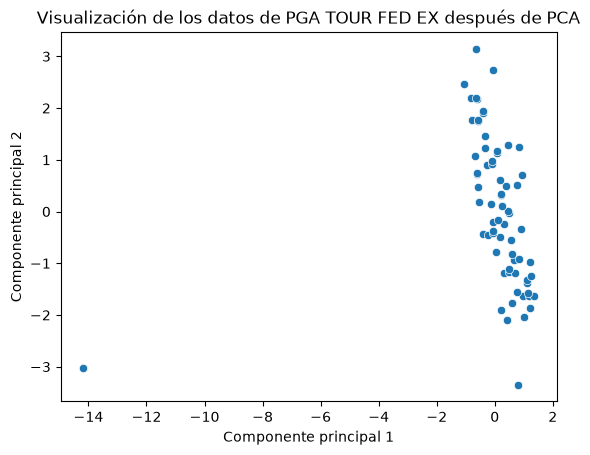

In [7]:
import seaborn as sns
sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1])
plt.title("Visualización de los datos de PGA TOUR FED EX después de PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

Text(0, 0.5, 'Componente principal 2')

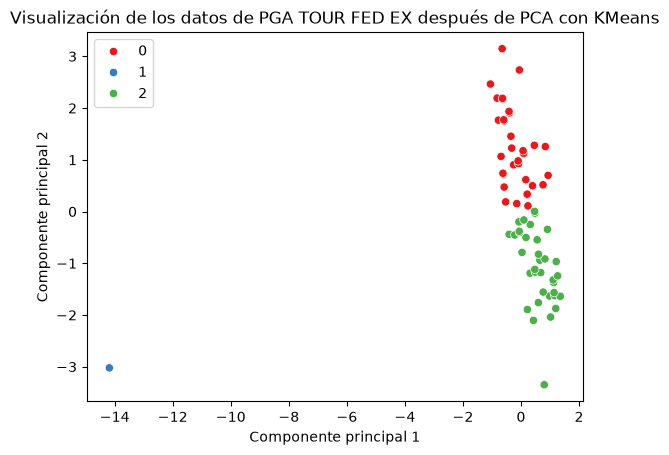

In [8]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(data_pca)

sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1], hue=kmeans.labels_, palette='Set1')
plt.title("Visualización de los datos de PGA TOUR FED EX después de PCA con KMeans")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

In [9]:
kmeans.labels_


array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1], dtype=int32)

In [10]:
data_clusters = pd.concat(
    [data_pga.reset_index(drop=True), pd.DataFrame(kmeans.labels_, columns=["Cluster"])],
    axis=1
)

display(data_clusters.head(50))

,posicion,score,ronda1,ronda2,ronda3,ronda4,Cluster
0,1,-17,68,61,68,66,2
1,2,-9,70,68,65,68,2
2,3,-8,71,66,66,69,2
3,4,-8,67,70,62,73,2
4,5,-7,69,66,70,68,2
5,6,-7,66,66,67,74,2
6,7,-6,67,72,68,67,2
7,8,-6,68,65,74,67,2
8,9,-6,66,70,67,71,2
9,10,-6,65,70,67,72,2


In [11]:
data_clusters.dtypes

data_clusters['score'] = data_clusters['score'].astype(float)

data_clusters.dtypes

posicion      int64
score       float64
ronda1        int64
ronda2        int64
ronda3        int64
ronda4        int64
Cluster       int32
dtype: object

In [12]:
data_clusters.groupby('Cluster').mean()

,posicion,score,ronda1,ronda2,ronda3,ronda4
Cluster,,,,,,
0,51.969697,3.424242,70.454545,70.666667,71.090909,71.212121
1,69.000000,12.000000,82.000000,0.000000,0.000000,0.000000
2,18.028571,-4.828571,68.342857,68.485714,68.400000,69.942857


<Axes: ylabel='Cluster'>

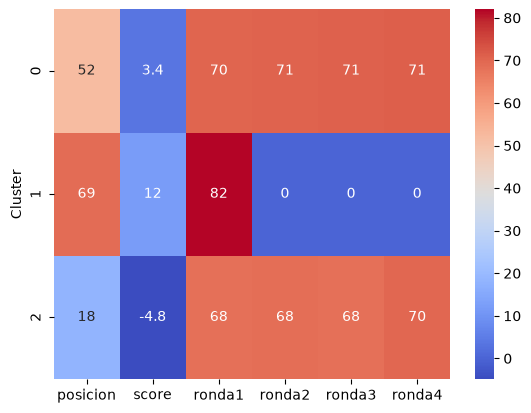

In [13]:
sns.heatmap(data_clusters.groupby('Cluster').mean(), annot=True, cmap='coolwarm')

In [14]:
data_clusters.to_csv("FedEx St. Jude Championship.csv", index=False)